In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Clustering algorithms
from sklearn.cluster import KMeans, DBSCAN

# Evaluation
from sklearn.metrics import silhouette_score

# Dimensionality reduction
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Other libraries
import warnings
warnings.filterwarnings("ignore")

# Reproducibility
np.random.seed(42)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

# Load uploaded CSV file
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving Mall_Customers.csv to Mall_Customers.csv
Dataset loaded successfully!
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
# Display first five rows
display(df.head())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Statistical Summary:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000



Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Records: 0

Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


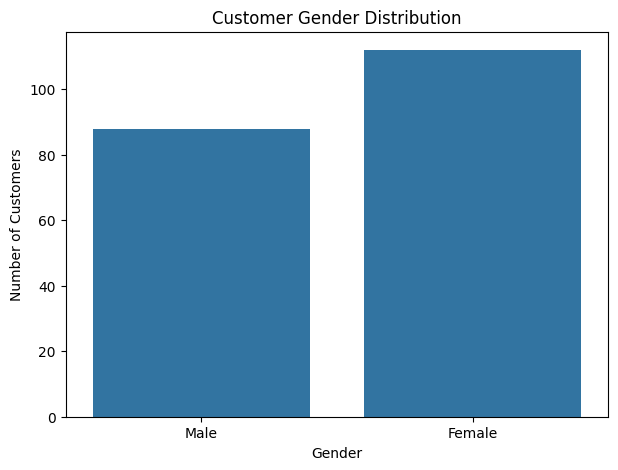

In [5]:
# Customer gender distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Gender")

plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

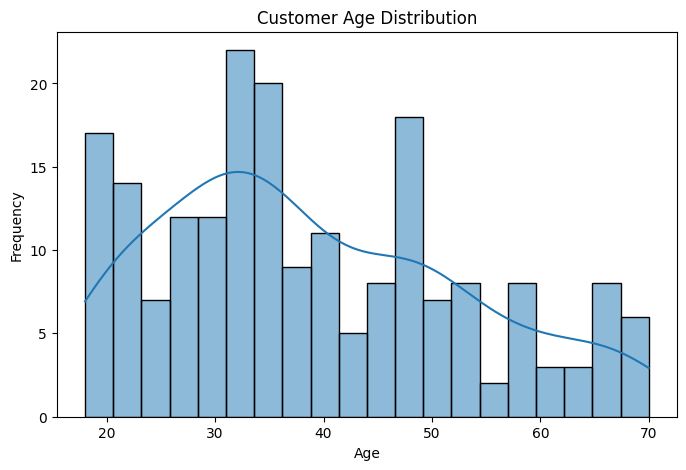

In [6]:
# Age distribution
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=20, kde=True)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

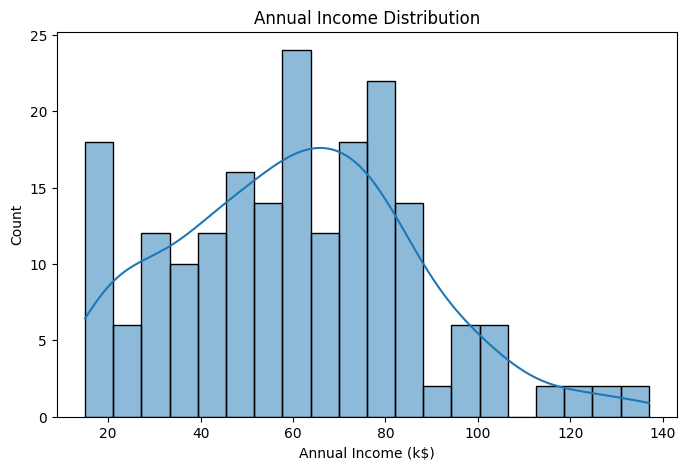

In [7]:
# Annual income distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Annual Income (k$)",
    bins=20,
    kde=True
)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income (k$)")
plt.show()

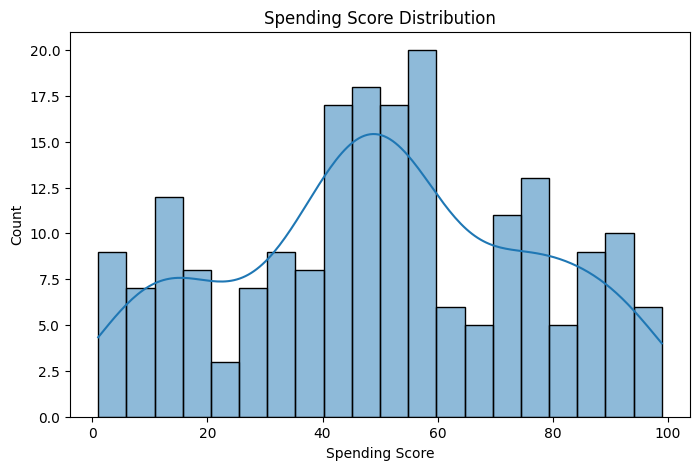

In [8]:
# Spending score distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Spending Score (1-100)",
    bins=20,
    kde=True
)

plt.title("Spending Score Distribution")
plt.xlabel("Spending Score")
plt.show()

In [9]:
# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove duplicate records
df = df.drop_duplicates().copy()

# Handle missing values in numeric columns
numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

# Handle missing categorical values
categorical_columns = df.select_dtypes(
    exclude=np.number
).columns

for column in categorical_columns:
    if df[column].isnull().any():
        df[column] = df[column].fillna(
            df[column].mode()[0]
        )

# Select clustering features
features = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[features]

print("\nData prepared successfully!")
display(X.head())

Missing values before cleaning:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Data prepared successfully!


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [10]:
# Apply StandardScaler
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")
print("Scaled data shape:", X_scaled.shape)

Feature scaling completed!
Scaled data shape: (200, 2)


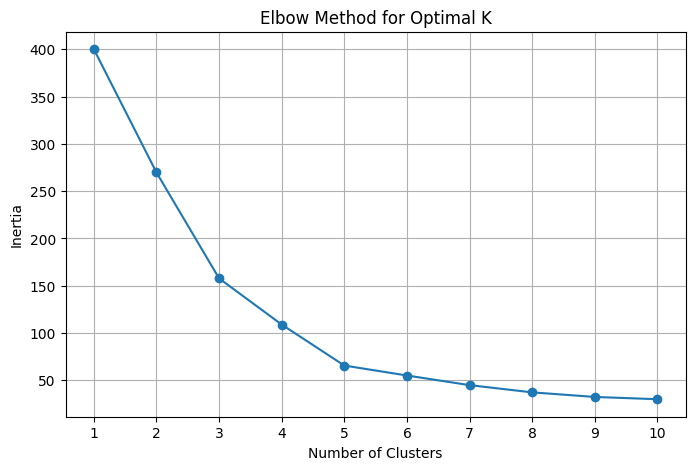

In [11]:
inertia_values = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)

# Plot Elbow Method
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

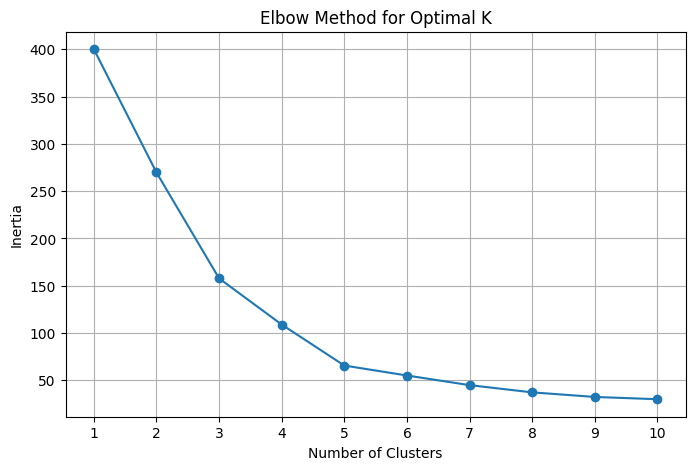

In [12]:
inertia_values = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)

# Plot Elbow Method
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [13]:
# Apply K-Means
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")

# Display cluster counts
print("\nCustomers in Each Cluster:")
print(df["KMeans_Cluster"].value_counts().sort_index())

K-Means clustering completed!

Customers in Each Cluster:
KMeans_Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


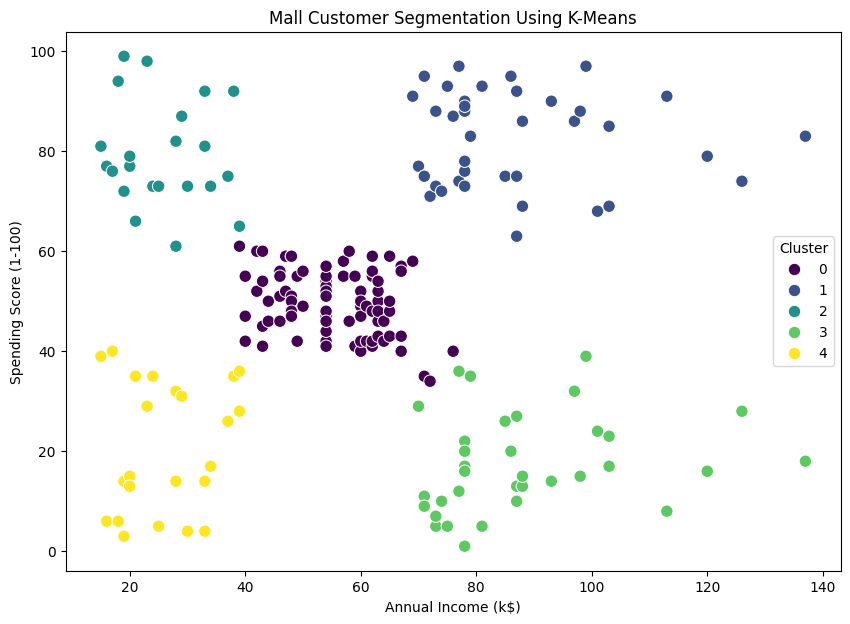

In [14]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="KMeans_Cluster",
    palette="viridis",
    s=80
)

plt.title("Mall Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

In [15]:
kmeans_score = silhouette_score(
    X_scaled,
    df["KMeans_Cluster"]
)

print("K-Means Silhouette Score:", round(kmeans_score, 4))

K-Means Silhouette Score: 0.5547


In [16]:
# Apply DBSCAN
dbscan = DBSCAN(
    eps=0.35,
    min_samples=5
)

df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print("DBSCAN clustering completed!")

print("\nDBSCAN Cluster Distribution:")
print(df["DBSCAN_Cluster"].value_counts().sort_index())

# Count noise points
noise_count = (df["DBSCAN_Cluster"] == -1).sum()

print("\nNoise Points:", noise_count)

DBSCAN clustering completed!

DBSCAN Cluster Distribution:
DBSCAN_Cluster
-1    23
 0    16
 1    12
 2     7
 3    88
 4    31
 5    23
Name: count, dtype: int64

Noise Points: 23


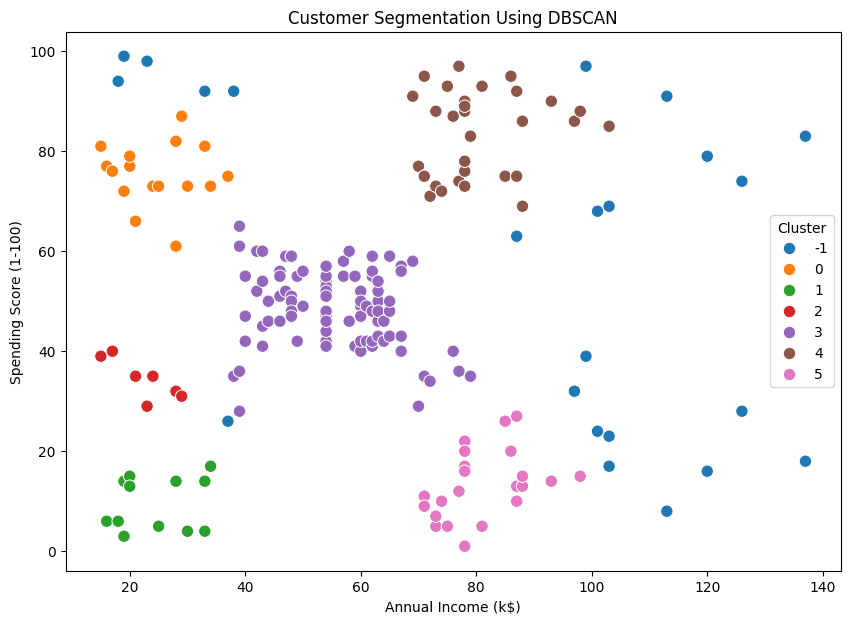

In [17]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="DBSCAN_Cluster",
    palette="tab10",
    s=80
)

plt.title("Customer Segmentation Using DBSCAN")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

In [18]:
dbscan_labels = df["DBSCAN_Cluster"].values

# Exclude noise points
non_noise_mask = dbscan_labels != -1

valid_labels = dbscan_labels[non_noise_mask]
valid_data = X_scaled[non_noise_mask]

unique_clusters = np.unique(valid_labels)

if len(unique_clusters) >= 2:
    dbscan_score = silhouette_score(
        valid_data,
        valid_labels
    )

    print(
        "DBSCAN Silhouette Score:",
        round(dbscan_score, 4)
    )
else:
    dbscan_score = None
    print(
        "Silhouette Score cannot be calculated: "
        "DBSCAN found fewer than two non-noise clusters."
    )

DBSCAN Silhouette Score: 0.5577


,Algorithm,Silhouette Score
0,K-Means,0.554657
1,DBSCAN,0.557746


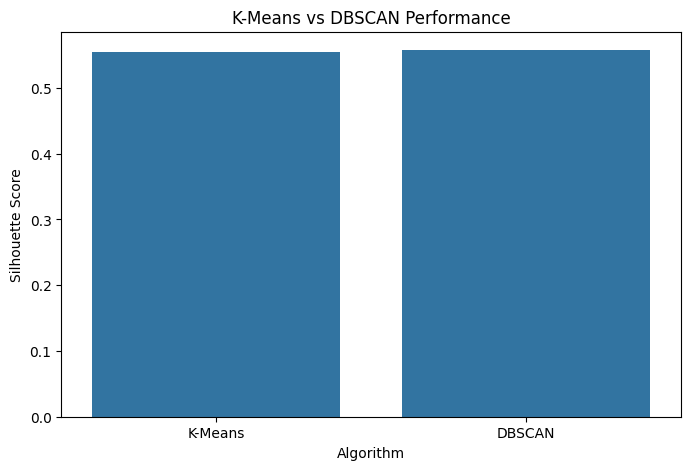

In [19]:
comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "DBSCAN"],
    "Silhouette Score": [
        kmeans_score,
        dbscan_score
    ]
})

display(comparison)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison.dropna(),
    x="Algorithm",
    y="Silhouette Score"
)

plt.title("K-Means vs DBSCAN Performance")
plt.ylabel("Silhouette Score")
plt.show()

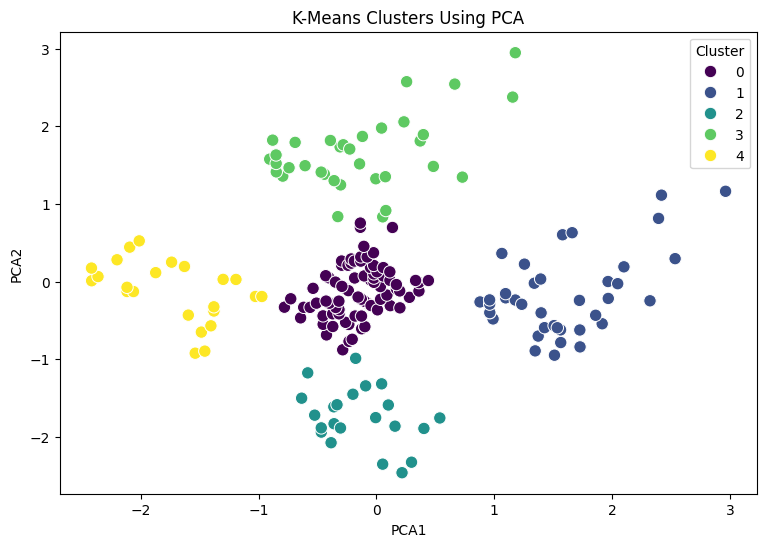

Explained variance: 1.0


In [20]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PCA1": X_pca[:, 0],
    "PCA2": X_pca[:, 1],
    "Cluster": df["KMeans_Cluster"]
})

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette="viridis",
    s=80
)

plt.title("K-Means Clusters Using PCA")
plt.show()

print(
    "Explained variance:",
    pca.explained_variance_ratio_.sum()
)

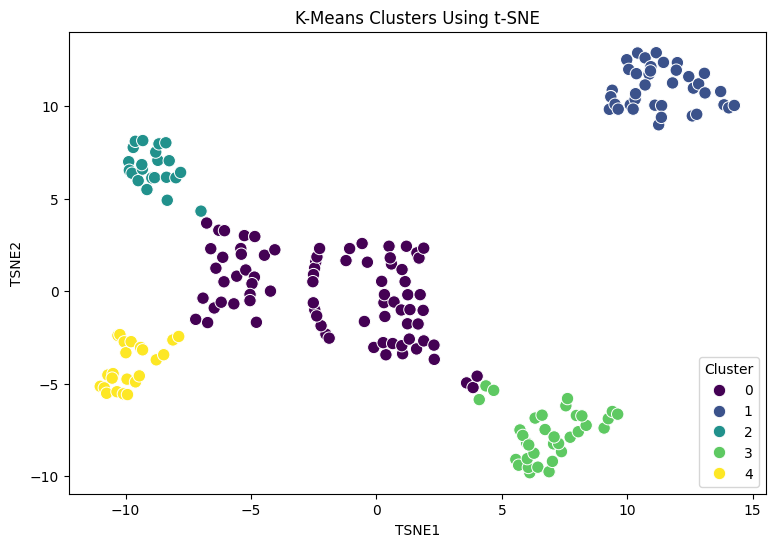

In [21]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=min(30, len(X_scaled) - 1),
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_scaled)

tsne_df = pd.DataFrame({
    "TSNE1": X_tsne[:, 0],
    "TSNE2": X_tsne[:, 1],
    "Cluster": df["KMeans_Cluster"]
})

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=tsne_df,
    x="TSNE1",
    y="TSNE2",
    hue="Cluster",
    palette="viridis",
    s=80
)

plt.title("K-Means Clusters Using t-SNE")
plt.show()

In [22]:
# Calculate average customer characteristics
cluster_summary = df.groupby("KMeans_Cluster").agg({
    "Annual Income (k$)": "mean",
    "Spending Score (1-100)": "mean",
    "Age": "mean",
    "CustomerID": "count"
}).round(2)

cluster_summary = cluster_summary.rename(
    columns={"CustomerID": "Customer Count"}
)

print("Customer Segment Analysis:")
display(cluster_summary)

Customer Segment Analysis:


,Annual Income (k$),Spending Score (1-100),Age,Customer Count
KMeans_Cluster,,,,
0,55.30,49.52,42.72,81
1,86.54,82.13,32.69,39
2,25.73,79.36,25.27,22
3,88.20,17.11,41.11,35
4,26.30,20.91,45.22,23


In [24]:
# Save customer segmentation results
df.to_csv(
    "Mall_Customer_Segmentation_Results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


In [25]:
from google.colab import files

files.download("Mall_Customer_Segmentation_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>